# 04 — Fairness and explainable-AI audit

Answers RQ3 with subgroup outcome/performance metrics, bootstrap disparity intervals, global permutation importance and a clear statement that association is not causation.

**Reproducibility rule:** outputs below are generated from the untouched held-out test set or from validation/CV reports; no test result is used to fit the model or choose thresholds.

In [1]:
from pathlib import Path
import json
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import (precision_recall_curve, roc_curve, auc,
                             confusion_matrix, ConfusionMatrixDisplay)

warnings.filterwarnings("ignore", category=FutureWarning)
ROOT = Path.cwd()
PUB = ROOT / "publication"
FIGURES = PUB / "figures"
TABLES = PUB / "tables"
FIGURES.mkdir(parents=True, exist_ok=True)
TABLES.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({
    "figure.dpi": 120, "savefig.dpi": 300, "font.size": 10,
    "axes.titlesize": 12, "axes.labelsize": 10,
    "axes.spines.top": False, "axes.spines.right": False,
})
BLUE, GOLD, RED, GREEN, GREY = "#1f4e79", "#d89b2b", "#b03a2e", "#2e7d32", "#6b7280"

In [2]:
groups = pd.read_csv(ROOT / "reports" / "fairness_by_group.csv")
gaps = pd.read_csv(ROOT / "reports" / "fairness_gaps.csv")
ci = pd.read_csv(ROOT / "reports" / "fairness_gap_confidence_intervals.csv")
importance = pd.read_csv(ROOT / "reports" / "permutation_importance.csv")
gaps

,attribute,groups_included,demographic_parity_difference,demographic_parity_ratio,equal_opportunity_difference,false_positive_rate_difference,predictive_parity_difference,mean_score_difference
0,AgeBand,6,0.162869,0.598645,0.343750,0.142203,0.131064,0.029787
1,MaritalStatus,2,0.006614,0.975845,0.072464,0.009772,0.024943,0.000255
2,Sex,2,0.063951,0.771211,0.089431,0.051376,0.042116,0.011557
3,Sex_x_AgeBand,11,0.212464,0.476429,0.666667,0.198536,0.239203,0.042970


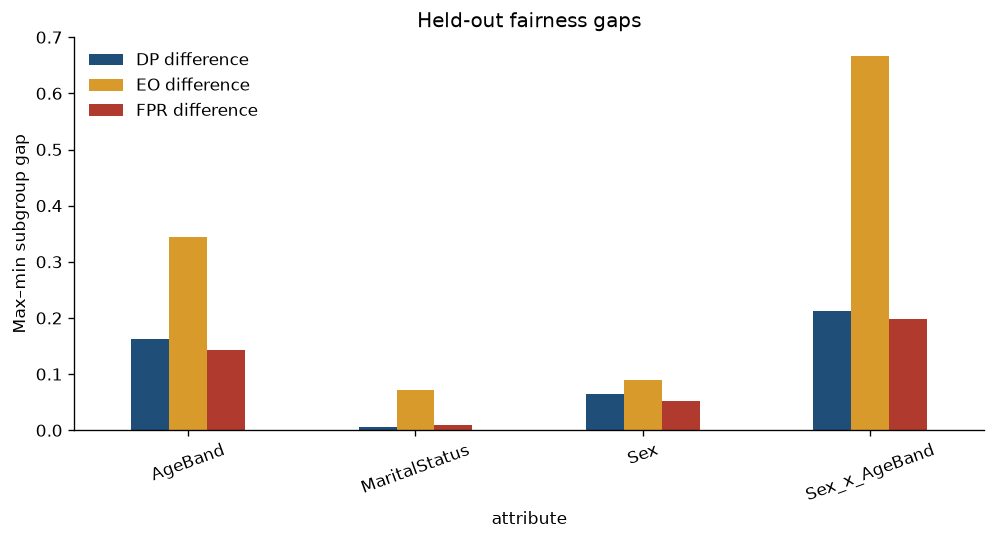

In [3]:
gaps.to_csv(TABLES / "table_06_fairness_gaps.csv", index=False)
ci.to_csv(TABLES / "table_07_fairness_bootstrap_ci.csv", index=False)
importance.head(15).to_csv(TABLES / "table_08_feature_importance.csv", index=False)
(TABLES / "table_06_fairness_gaps.tex").write_text(gaps.to_latex(index=False, escape=True, float_format="%.4f"), encoding="utf-8")

plot_gap = gaps.set_index("attribute")[["demographic_parity_difference", "equal_opportunity_difference", "false_positive_rate_difference"]]
ax = plot_gap.plot(kind="bar", figsize=(8.4, 4.6), color=[BLUE, GOLD, RED])
ax.set_ylabel("Max–min subgroup gap"); ax.set_title("Held-out fairness gaps"); ax.tick_params(axis="x", rotation=20); ax.legend(["DP difference", "EO difference", "FPR difference"], frameon=False)
ax.figure.tight_layout(); ax.figure.savefig(FIGURES / "figure_05_fairness_gaps.png", bbox_inches="tight"); plt.show()

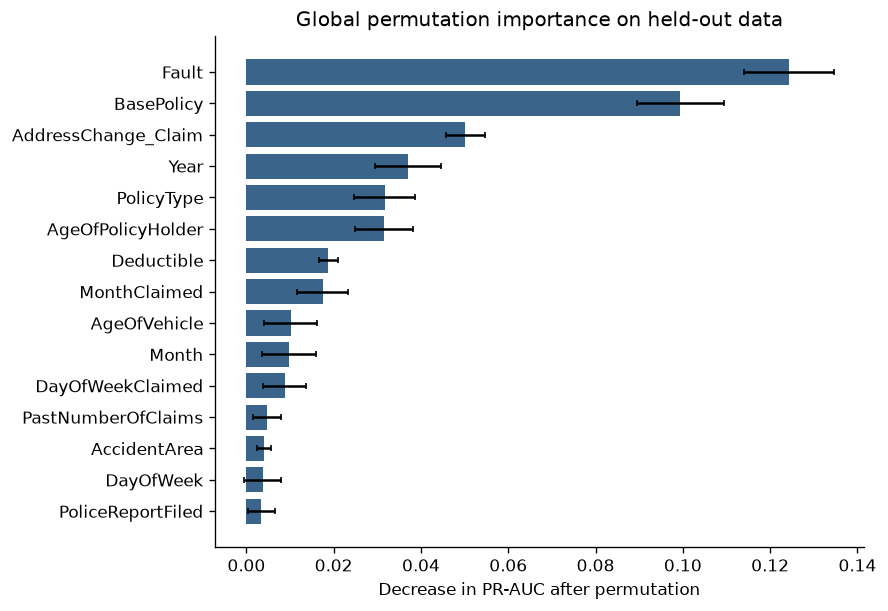

In [4]:
top = importance.head(15).sort_values("importance_mean")
fig, ax = plt.subplots(figsize=(7.5, 5.2))
ax.barh(top["feature"], top["importance_mean"], xerr=top["importance_std"], color=BLUE, alpha=.88, capsize=2)
ax.set_xlabel("Decrease in PR-AUC after permutation"); ax.set_title("Global permutation importance on held-out data")
fig.tight_layout(); fig.savefig(FIGURES / "figure_06_permutation_importance.png", bbox_inches="tight"); plt.show()

Sex, Age and MaritalStatus were excluded from model inputs but retained for post-hoc audit. The remaining disparities therefore show that removing protected fields alone does not guarantee parity: non-protected variables can encode population structure or proxy effects. Intersectional intervals are wide because several fraud-positive subgroups are small.